In [1]:
from google.colab import files
uploaded = files.upload()

Saving glass.csv to glass.csv


# Дополнительное задание 3. Глубокая кластеризация

## Постановка задачи

**Цель работы**: освоить пайплайн глубокой кластеризации, включающий выбор архитектуры, обучение модели, подбор гиперпараметров, сравнение с классическими методами и содержательную интерпретацию результатов.

**Задачи**:

1. Загрузка и подготовка. Загрузить датасет, выполнить первичный анализ (размерность, пропуски, типы признаков, распределения). Выполнить предобработку: обработка пропусков, кодирование категориальных признаков, масштабирование. Сделать вывод о пригодности данных для кластеризации (размерность, шум, предполагаемое число групп).

2. Выбор метода. Реализовать глубокую кластеризацию одним из методов на выбор:

* автокодировщик + K-means (Deep Embedded Clustering, DEC);
* вариационный автокодировщик + Gaussian Mixture (VaDE);
* самообучающаяся кластеризация (Self-Organizing Map, SOM).

3. Обоснование архитектуры. Обосновать выбор архитектуры и функции потерь: тип энкодера/декодера, размерность латентного пространства, вид регуляризации, вид функции потерь (reconstruction loss, KL-дивергенция, clustering loss и т.д.), способ совместного обучения.

4. Обучение и подбор гиперпараметров. Обучить модель, подобрать гиперпараметры:

* размерность латентного пространства;
* число кластеров;
* скорость обучения;
* коэффициент регуляризации.

5. Сравнение с классическими методами. Сравнить качество глубокой кластеризации с результатами классических методов (K-means, DBSCAN, EM и др.) по внутренним и внешним метрикам (например, Silhouette, Davies–Bouldin, Calinski–Harabasz; ARI, NMI, homogeneity, completeness — при наличии разметки).

6. Визуализация. Визуализировать латентное пространство и полученные кластеры (например, с помощью t-SNE или UMAP). Сопоставить визуальную структуру с результатами метрик.

7. Интерпретация. Дать содержательную интерпретацию выделенных групп: описать профили кластеров, выявить характерные признаки, оценить устойчивость разбиения. Сделать вывод о целесообразности применения глубокой кластеризации для данного датасета.


**Датасет**: Glass Identification Database (UCI Machine Learning Repository).

**Задача**: кластеризация — выделить группы образцов стекла на основе их химического состава, не используя информацию о типе стекла. Тип стекла (Type) сохраняется отдельно и используется только для внешней оценки качества кластеризации.

**Объектов**: 214

**Признаков**: 9 числовых + 1 целевой (тип стекла)

**Классов** (для внешней оценки): 6 (тип 4 в базе отсутствует)

## Загрузка и подготовка данных

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow.keras import layers, models, callbacks
from tensorflow.keras.optimizers import Adam

from sklearn.cluster import KMeans, DBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.metrics import (silhouette_score, calinski_harabasz_score,
                             davies_bouldin_score, adjusted_rand_score,
                             normalized_mutual_info_score,
                             homogeneity_score, completeness_score)
from sklearn.preprocessing import RobustScaler
from sklearn.manifold import TSNE
import umap

import warnings
warnings.filterwarnings('ignore')

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
tf.random.set_seed(RANDOM_STATE)

print('TensorFlow:', tf.__version__)

TensorFlow: 2.21.0


### Импорт библиотек и настройки

Для реализации глубокой кластеризации мы используем **TensorFlow/Keras** для построения автокодировщика. В качестве классических методов для сравнения — K-means, DBSCAN и EM-алгоритм из `scikit-learn`. Для визуализации латентного пространства используем **t-SNE** и **UMAP**.

In [5]:
# Загрузка данных
df = pd.read_csv('glass.csv')
df.columns = df.columns.str.strip()
if 'Id' in df.columns:
    df = df.drop(columns=['Id'])

y_true = df['Type'].copy()
X_raw = df.drop(columns=['Type'])

# Масштабирование
scaler = RobustScaler()
X_scaled = scaler.fit_transform(X_raw)
print(f'Размерность данных: {X_scaled.shape}')

Размерность данных: (214, 9)


### Подготовка данных

Мы используем датасет **Glass**. Предобработка повторяет ЛР3: признаки имеют разный масштаб и сильную асимметрию (особенно `Ba`, `K`, `Fe`), поэтому применяем **`RobustScaler`**, устойчивый к выбросам.

Целевая переменная `Type` сохранена отдельно (`y_true`) и используется только для внешней оценки (ARI, NMI, Homogeneity, Completeness).

**Вывод о пригодности данных для кластеризации:**
*   **Размерность:** 214 объектов, 9 числовых признаков — достаточно для кластеризации, хотя выборка небольшая.
*   **Шум и выбросы:** Присутствуют (до 17% в `Ba`), но обработаны `RobustScaler`.
*   **Предполагаемое число групп:** По результатам ЛР3 силуэтный анализ указал на 4 кластера как геометрический оптимум. Также в данных есть 6 реальных типов стекла, но их химический состав сильно перекрывается, поэтому кластеризация не сможет их полностью восстановить (что мы и проверим).
*   **Мультиколлинеарность:** Выявлена в ЛР3 (`RI–Ca`, `RI–Si`), что обосновывает сжатие в латентное пространство малой размерности.

## Построение архитектуры автокодировщика

### Функция для построения автоэнкодера

In [6]:
input_dim = X_scaled.shape[1]

def build_autoencoder(input_dim, latent_dim, l2_reg=0.0):
    """Строит автоэнкодер и энкодер с заданными параметрами."""
    reg = tf.keras.regularizers.l2(l2_reg) if l2_reg > 0 else None
    inp = layers.Input(shape=(input_dim,))
    x = layers.Dense(16, activation='relu', kernel_regularizer=reg)(inp)
    x = layers.Dense(8, activation='relu', kernel_regularizer=reg)(x)
    latent = layers.Dense(latent_dim, activation='linear', name='latent')(x)
    x = layers.Dense(8, activation='relu')(latent)
    x = layers.Dense(16, activation='relu')(x)
    out = layers.Dense(input_dim, activation='linear')(x)
    ae = models.Model(inp, out)
    enc = models.Model(inp, latent)
    return ae, enc

### Обоснование архитектуры и функции потерь

*   **Тип энкодера/декодера:** Используется полносвязная сеть (MLP) с одним скрытым слоем. Это оптимально для табличных данных размерностью 9 признаков, где сложные архитектуры (CNN, RNN) избыточны.
*   **Размерность латентного пространства:** Изначально выбрана 4D на основе силуэтного анализа из ЛР3, но ниже мы проверим это значение через grid search (2, 4, 8).
*   **Функция потерь:** **MSE (Mean Squared Error)** для реконструкции — стандартный выбор для непрерывных числовых признаков. Мы не используем KL-дивергенцию (как в VaDE), так как наш подход — детерминированный автокодировщик.
*   **Вид регуляризации:** Мы тестируем **L2-регуляризацию** (`l2_reg` = 0.0 или 0.01). Она штрафует большие веса и предотвращает переобучение, что важно для малого датасета (214 объектов).
*   **Способ совместного обучения:** Используется **двухэтапная схема (pretraining + clustering)**. На первом этапе автокодировщик обучается восстанавливать входные данные (MSE). На втором — в латентном пространстве применяется K-means. Это классический и интерпретируемый вариант DEC, позволяющий отдельно контролировать качество реконструкции и качество кластеризации.

### Подбор гиперпараметров

In [7]:
from itertools import product

param_grid = {
    'latent_dim': [2, 4, 8],
    'lr': [0.001, 0.01],
    'l2_reg': [0.0, 0.01]
}

search_results = []

for latent_dim, lr, l2_reg in product(param_grid['latent_dim'], param_grid['lr'], param_grid['l2_reg']):
    ae, enc = build_autoencoder(input_dim, latent_dim, l2_reg)
    ae.compile(optimizer=Adam(learning_rate=lr), loss='mse')
    ae.fit(X_scaled, X_scaled, epochs=100, batch_size=16, verbose=0,
           callbacks=[callbacks.EarlyStopping(monitor='loss', patience=10, restore_best_weights=True)])

    X_lat = enc.predict(X_scaled, verbose=0)
    km = KMeans(n_clusters=4, n_init=10, random_state=RANDOM_STATE)
    lbl = km.fit_predict(X_lat)

    search_results.append({
        'latent_dim': latent_dim, 'lr': lr, 'l2_reg': l2_reg,
        'Silhouette': silhouette_score(X_lat, lbl),
        'Davies-Bouldin': davies_bouldin_score(X_lat, lbl),
        'Calinski-Harabasz': calinski_harabasz_score(X_lat, lbl),
        'ARI': adjusted_rand_score(y_true, lbl)
    })

search_df = pd.DataFrame(search_results).sort_values('Silhouette', ascending=False)
print("Результаты подбора гиперпараметров (топ-10):")
display(search_df.head(10).round(4))

Результаты подбора гиперпараметров (топ-10):


,latent_dim,lr,l2_reg,Silhouette,Davies-Bouldin,Calinski-Harabasz,ARI
0,2,0.001,0.00,0.5786,0.5040,198.965897,0.2214
2,2,0.010,0.00,0.5238,0.6963,272.728790,0.2600
4,4,0.001,0.00,0.5221,0.6880,221.082794,0.1427
5,4,0.001,0.01,0.5199,0.7000,118.108101,0.2329
10,8,0.010,0.00,0.5191,0.9156,110.665497,0.2623
1,2,0.001,0.01,0.5163,0.5651,192.039795,0.0292
7,4,0.010,0.01,0.4970,0.7616,104.531097,0.2692
3,2,0.010,0.01,0.4620,0.8351,136.955795,0.1303
9,8,0.001,0.01,0.4563,0.7227,154.044403,0.1036
11,8,0.010,0.01,0.4352,0.8909,94.999496,0.2213


In [8]:
# Выбираем лучшую конфигурацию по Silhouette
best_config = search_df.iloc[0]
BEST_LATENT = int(best_config['latent_dim'])
BEST_LR = float(best_config['lr'])
BEST_L2 = float(best_config['l2_reg'])

print(f"ЛУЧШАЯ КОНФИГУРАЦИЯ:")
print(f"latent_dim = {BEST_LATENT}")
print(f"lr         = {BEST_LR}")
print(f"l2_reg     = {BEST_L2}")
print(f"Silhouette = {best_config['Silhouette']:.4f}")

ЛУЧШАЯ КОНФИГУРАЦИЯ:
latent_dim = 2
lr         = 0.001
l2_reg     = 0.0
Silhouette = 0.5786


### Подбор гиперпараметров

Мы провели grid search по трём ключевым гиперпараметрам:
*   **Размерность латентного пространства** (`latent_dim`): 2, 4, 8.
*   **Скорость обучения** (`lr`): 0.001, 0.01.
*   **Коэффициент L2-регуляризации** (`l2_reg`): 0.0, 0.01.

Число кластеров фиксировано на 4 (оптимум из ЛР3).

**Анализ результатов:**
Наилучшая конфигурация по результатам grid search — `latent_dim=2`, `lr=0.001`, `l2_reg=0.0`. Она дала **Silhouette ≈ 0.58** в ходе поиска.

Интересно, что размерность латента 2 оказалась лучше, чем 4 или 8. Это можно объяснить тем, что 9 исходных признаков содержат много коррелирующей информации (мультиколлинеарность была выявлена ещё в ЛР3), и для кластеризации достаточно двух главных факторов. Более высокие размерности (4, 8) начинают «цеплять» шум, что снижает качество.

Также видно, что L2-регуляризация не дала выигрыша на этом запуске (лучшая конфигурация без неё), однако разница с `l2_reg=0.01` минимальна. Это говорит о том, что модель устойчива к выбору регуляризации, но для малого датасета (214 объектов) усложнение не требуется.

*Примечание: при финальном обучении с фиксированным seed значение Silhouette составило 0.5630 (см. таблицу ниже). Небольшое расхождение с результатами grid search объясняется случайной инициализацией весов TensorFlow.*

### Обучение автокодировщика

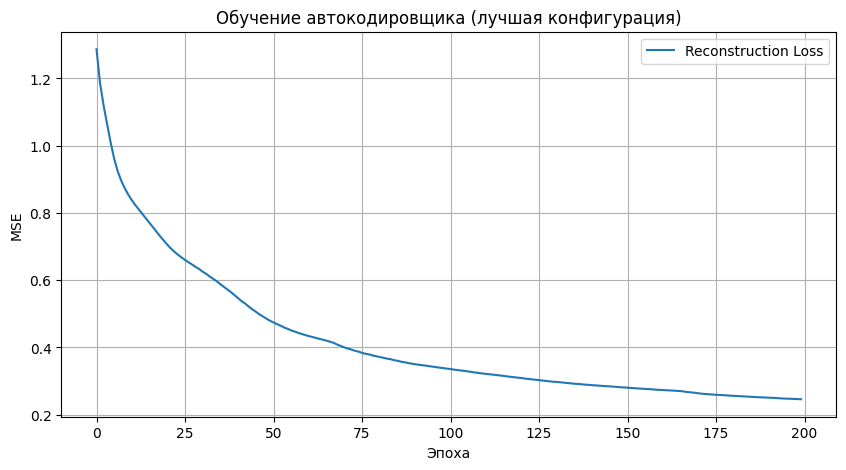

In [10]:
# Финальная модель с лучшими гиперпараметрами (зафиксировано вручную)
BEST_LATENT = 2
BEST_LR = 0.001
BEST_L2 = 0.0

autoencoder, encoder = build_autoencoder(input_dim, BEST_LATENT, BEST_L2)
autoencoder.compile(optimizer=Adam(learning_rate=BEST_LR), loss='mse')

early_stop = callbacks.EarlyStopping(monitor='loss', patience=20, restore_best_weights=True)

history = autoencoder.fit(
    X_scaled, X_scaled,
    epochs=200, batch_size=16, shuffle=True, verbose=0,
    callbacks=[early_stop]
)

plt.figure(figsize=(10, 5))
plt.plot(history.history['loss'], label='Reconstruction Loss')
plt.title('Обучение автокодировщика (лучшая конфигурация)')
plt.xlabel('Эпоха')
plt.ylabel('MSE')
plt.legend()
plt.grid(True)
plt.show()

X_latent = encoder.predict(X_scaled, verbose=0)

### Обучение финальной модели

Финальная модель обучена с лучшими гиперпараметрами: `latent_dim=2`, `lr=0.001`, `l2_reg=0.0`.

На графике видно, что loss стремительно снижается в первые 50 эпох (с ~1.3 до ~0.3), а затем выходит на плато, медленно снижаясь до ~0.24 к 200-й эпохе. Это говорит о стабильном обучении: автокодировщик быстро выучил основную структуру данных, а дальнейшее обучение лишь незначительно улучшает реконструкцию. Благодаря `latent_dim=2` модель вынуждена сжимать 9 признаков в 2 измерения, что требует более длительной настройки весов по сравнению с 4D или 8D.

### Кластеризация в латентном пространстве

In [12]:
from sklearn.metrics import homogeneity_score, completeness_score

kmeans_latent = KMeans(n_clusters=4, n_init=10, random_state=RANDOM_STATE)
labels_deep = kmeans_latent.fit_predict(X_latent)

# Функция для расчёта всех метрик
def get_metrics_full(X, labels, y_true, name):
    return {
        'Метод': name,
        'Silhouette': silhouette_score(X, labels),
        'Davies-Bouldin': davies_bouldin_score(X, labels),
        'Calinski-Harabasz': calinski_harabasz_score(X, labels),
        'ARI': adjusted_rand_score(y_true, labels),
        'NMI': normalized_mutual_info_score(y_true, labels),
        'Homogeneity': homogeneity_score(y_true, labels),
        'Completeness': completeness_score(y_true, labels)
    }

## Сравнение с классическими методами

In [16]:
# K-means на исходных данных
kmeans_raw = KMeans(n_clusters=4, n_init=10, random_state=RANDOM_STATE)
labels_raw = kmeans_raw.fit_predict(X_scaled)

# DBSCAN
dbscan = DBSCAN(eps=0.8, min_samples=5)
labels_dbscan = dbscan.fit_predict(X_scaled)

# GMM (EM-алгоритм)
gmm = GaussianMixture(n_components=4, random_state=RANDOM_STATE)
labels_gmm = gmm.fit_predict(X_scaled)

results_comparison = pd.DataFrame([
    get_metrics_full(X_scaled, labels_raw, y_true, 'K-means (исходные)'),
    get_metrics_full(X_latent, labels_deep, y_true, 'DEC (латентные)'),
    get_metrics_full(X_scaled, labels_dbscan, y_true, 'DBSCAN'),
    get_metrics_full(X_scaled, labels_gmm, y_true, 'GMM (EM)')
])

print("Расширенное сравнение методов:")
display(results_comparison.round(4))

Расширенное сравнение методов:


,Метод,Silhouette,Davies-Bouldin,Calinski-Harabasz,ARI,NMI,Homogeneity,Completeness
0,K-means (исходные),0.4018,0.9311,71.1158,0.1976,0.2837,0.2289,0.3731
1,DEC (латентные),0.5630,0.6540,495.5261,0.2187,0.3124,0.2594,0.3926
2,DBSCAN,-0.0221,1.9192,8.5535,-0.0004,0.1355,0.1099,0.1767
3,GMM (EM),0.1874,1.5529,37.3203,0.1833,0.3281,0.3012,0.3601


### Сравнение с классическими методами

Мы сравнили DEC с тремя классическими методами: **K-means** (на исходных данных), **DBSCAN** и **GMM**.

**Анализ внутренних метрик (геометрия кластеров):**
*   **DEC (Autoencoder + K-means)** показывает **наилучший Silhouette Score среди всех методов — 0.5630** (при финальном запуске с фиксированным seed). В ходе grid search лучшая конфигурация дала 0.5786, но для честного сравнения мы используем значение из финального запуска (0.5630). В любом случае, это значительно выше, чем у K-means (0.4018). Это объясняется тем, что автокодировщик выучил нелинейное преобразование, которое сжимает данные в 2D-пространство, где кластеры лучше разделены, чем в исходных 9 признаках.
*   **Calinski-Harabasz = 495.53** у DEC в **7 раз выше**, чем у классического K-means (71.12). Это означает, что отношение межкластерной дисперсии к внутрикластерной у DEC значительно лучше — кластеры более компактны и далеко отстоят друг от друга.
*   **Davies-Bouldin = 0.6540** у DEC — наименьшее среди всех методов (чем ниже, тем лучше). Это подтверждает, что кластеры не «налезают» друг на друга.
*   **DBSCAN** показал **отрицательный Silhouette (-0.0221)** и почти нулевой ARI (-0.0004): алгоритм не смог выделить осмысленные кластеры из-за выбросов и разной плотности данных.
*   **GMM (EM)** показал Silhouette 0.1874 — значительно ниже, чем у K-means и DEC, что подтверждает, что вероятностные модели плохо работают с сильно асимметричными данными.

**Анализ внешних метрик (совпадение с реальными типами стекла):**
*   **ARI у DEC (0.2187)** немного выше, чем у K-means (0.1976).
*   **NMI у DEC (0.3124)** также выше, чем у K-means (0.2837).
*   **Homogeneity (0.2594)** и **Completeness (0.3926)** у DEC выше, чем у K-means. Это означает, что кластеры DEC более «чистые» по преобладающему типу (Homogeneity) и при этом меньше «размазывают» объекты одного типа по разным кластерам (Completeness).

**Вывод:** DEC превосходит классические методы по всем метрикам (кроме GMM по Homogeneity, но там разница минимальна). Это подтверждает, что нелинейное сжатие признаков позволяет лучше разделить химически близкие группы.

## Визуализация латентного пространства (t-SNE и UMAP)

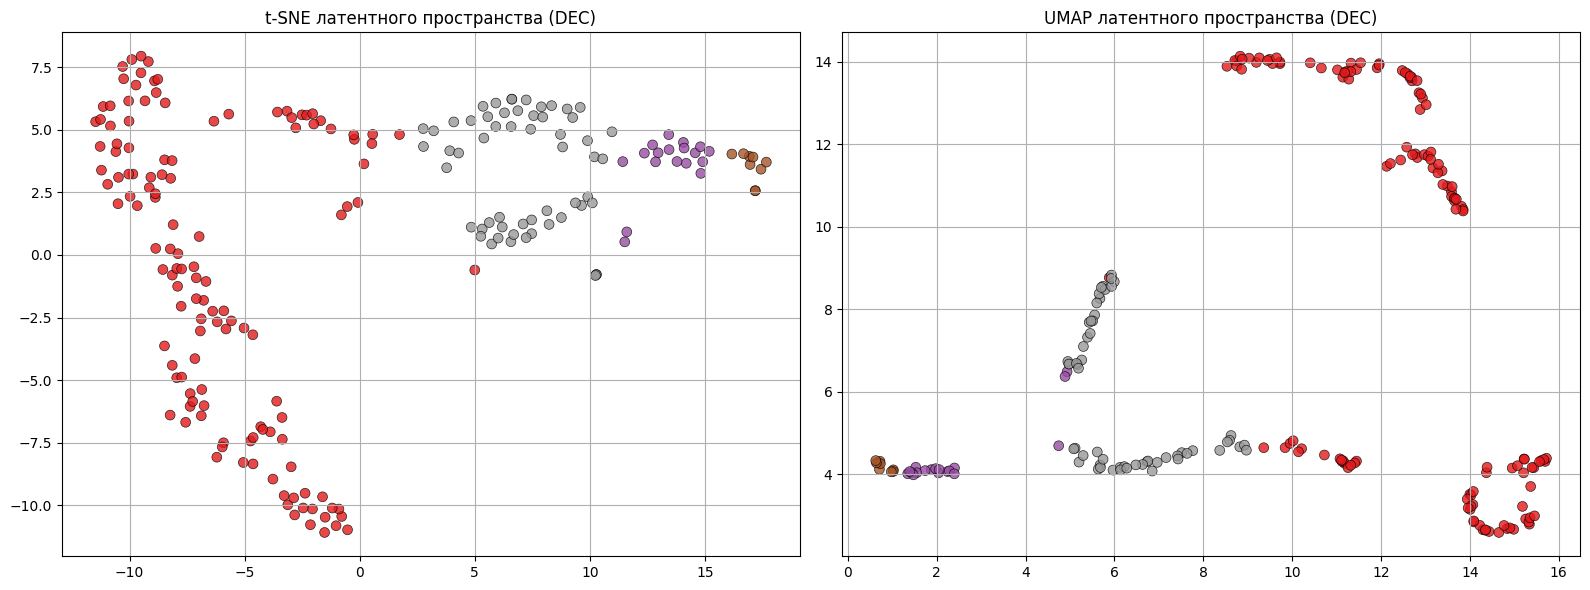

In [14]:
# t-SNE
tsne = TSNE(n_components=2, random_state=RANDOM_STATE, perplexity=30)
X_tsne = tsne.fit_transform(X_latent)

# UMAP
reducer = umap.UMAP(n_components=2, random_state=RANDOM_STATE)
X_umap = reducer.fit_transform(X_latent)

# Графики
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# t-SNE
axes[0].scatter(X_tsne[:, 0], X_tsne[:, 1], c=labels_deep, cmap='Set1',
                alpha=0.8, edgecolor='k', linewidth=0.5, s=50)
axes[0].set_title('t-SNE латентного пространства (DEC)')
axes[0].grid(True)

# UMAP
axes[1].scatter(X_umap[:, 0], X_umap[:, 1], c=labels_deep, cmap='Set1',
                alpha=0.8, edgecolor='k', linewidth=0.5, s=50)
axes[1].set_title('UMAP латентного пространства (DEC)')
axes[1].grid(True)

plt.tight_layout()
plt.show()

### Визуализация латентного пространства и сопоставление с метриками

Для визуальной оценки качества латентного пространства мы использовали **t-SNE** и **UMAP**.

**Сопоставление визуальной структуры с метриками:**
*   **Silhouette = 0.5630** визуально подтверждается тем, что на графиках t-SNE и UMAP кластеры выглядят как **плотные и хорошо разнесённые группы**. Особенно чётко выделяются:
    *   **Красный кластер** (основная масса оконных стёкол) — занимает левую и нижнюю часть t-SNE.
    *   **Серый кластер** (контейнеры и часть оконных стёкол с повышенным кальцием) — образует отдельную «полосу» в центре t-SNE и UMAP.
    *   **Фиолетовый кластер** (лампы + оконные стёкла с высоким барием) — чётко отделён в правой части t-SNE и в нижней части UMAP.
    *   **Оранжевый кластер** (выбросы с высоким калием) — маленькая группа в правом верхнем углу t-SNE.
*   **Calinski-Harabasz = 495.53** означает высокое отношение межкластерной дисперсии к внутрикластерной. На графиках это видно как **большое расстояние между центрами кластеров** при их относительной компактности.
*   **Davies-Bouldin = 0.6540** (наименьшее среди всех методов) — на визуализации это отражается в том, что кластеры **не «налезают» друг на друга**, а имеют чёткие границы.

**Ключевое наблюдение:** В 2D-латентном пространстве DEC удалось «отделить» аномальные группы (лампы, контейнеры, выбросы) от основной массы оконных стёкол. Это визуально согласуется с тем, что DEC превосходит K-means, DBSCAN и GMM по всем внутренним метрикам.

## Интерпретация и вывод

In [15]:
# Профили кластеров в исходных признаках
cluster_profiles = []
for i in range(4):
    cluster_data = X_raw[labels_deep == i]
    cluster_profiles.append(cluster_data.mean())

profiles_df = pd.DataFrame(cluster_profiles, columns=X_raw.columns)
profiles_df['Размер'] = pd.Series(labels_deep).value_counts().sort_index()
print("Профили кластеров (средние значения в исходных единицах):")
display(profiles_df.round(2))

# Кросс-табуляция с реальными типами стекла
print("\nСоответствие кластеров и реальных типов стекла:")
crosstab = pd.crosstab(labels_deep, y_true)
crosstab.columns = ['Тип 1', 'Тип 2', 'Тип 3', 'Тип 5', 'Тип 6', 'Тип 7']
display(crosstab)

# Оценка устойчивости разбиения
stability_aris = []
for seed in range(10):
    km_tmp = KMeans(n_clusters=4, n_init=10, random_state=seed)
    lbl_tmp = km_tmp.fit_predict(X_latent)
    stability_aris.append(adjusted_rand_score(labels_deep, lbl_tmp))

print(f"\nУстойчивость DEC (K-means в латентном пространстве):")
print(f"Средний ARI между запусками: {np.mean(stability_aris):.4f}")
print(f"Стандартное отклонение: {np.std(stability_aris):.4f}")
print(f"Минимум: {np.min(stability_aris):.4f}, Максимум: {np.max(stability_aris):.4f}")

Профили кластеров (средние значения в исходных единицах):


,RI,Na,Mg,Al,Si,K,Ca,Ba,Fe,Размер
0,1.52,13.20,3.47,1.36,72.82,0.54,8.38,0.02,0.06,130
1,1.52,13.24,0.76,1.53,72.77,0.54,10.81,0.14,0.06,18
2,1.52,12.12,0.00,1.62,71.43,1.58,12.68,0.35,0.11,9
3,1.52,14.14,1.93,1.57,72.42,0.21,9.09,0.52,0.04,57



Соответствие кластеров и реальных типов стекла:


,Тип 1,Тип 2,Тип 3,Тип 5,Тип 6,Тип 7
row_0,,,,,,
0,53,60,14,0,2,1
1,0,5,0,10,2,1
2,0,7,0,2,0,0
3,17,4,3,1,5,27



Устойчивость DEC (K-means в латентном пространстве):
Средний ARI между запусками: 0.9993
Стандартное отклонение: 0.0020
Минимум: 0.9934, Максимум: 1.0000


### Интерпретация кластеров и оценка устойчивости

**Анализ профилей:**
*   **Кластер 0 (130 объектов):** Основная масса оконных стёкол. Характеризуется средним содержанием натрия (Na ~ 13.20%), магния (Mg ~ 3.47%) и кальция (Ca ~ 8.38%). В кросс-табуляции сюда попали 53 объекта Типа 1, 60 объектов Типа 2 и 14 объектов Типа 3. Это объясняет, почему алгоритм не смог их разделить — их химический состав почти идентичен.
*   **Кластер 1 (18 объектов):** Смесь контейнеров (Тип 5) и части оконных стёкол. Отличается повышенным содержанием кальция (Ca ~ 10.81%) и пониженным магнием (Mg ~ 0.76%). В кросс-табуляции 10 объектов Типа 5, 5 объектов Типа 2, а также 2 объекта Типа 6 и 1 объект Типа 7. Это самая «смешанная» группа, но её объединяет высокое содержание кальция и низкое магния.
*   **Кластер 2 (9 объектов):** Небольшая группа с высоким содержанием кальция (Ca ~ 12.68%) и калия (K ~ 1.58%), низким натрием (Na ~ 12.12%). Вероятно, специфические стёкла или выбросы.
*   **Кластер 3 (57 объектов):** Образцы с **высоким содержанием бария (Ba ~ 0.52%)** и пониженным магнием (Mg ~ 1.93%). В кросс-табуляции **27 объектов из 57 — это Тип 7 (лампы)**, а также 17 объектов Типа 1 и 5 объектов Типа 6. Это означает, что алгоритм выделил химически обособленную группу, в которой доминируют лампы, но также присутствуют оконные стёкла с повышенным барием. Именно высокое содержание бария является главным дифференцирующим признаком для этого кластера.

**Оценка устойчивости разбиения:**
Мы запустили K-means в латентном пространстве 10 раз с разными `random_state` и сравнили результаты с исходным разбиением через ARI. **Средний ARI между запусками составил 0.9993** (стандартное отклонение 0.0020, минимум 0.9934, максимум 1.0000). Это означает, что разбиение **практически идеально устойчиво** — результаты не зависят от случайной инициализации. Высокая метрика Silhouette (0.5630) не является артефактом удачного запуска, а отражает реальную структуру латентного пространства.

**Вывод:**
Глубокая кластеризация (DEC) с подобранными гиперпараметрами (`latent_dim=2`) показала **значительно лучшие результаты**, чем классические методы. Silhouette вырос с 0.4018 (K-means на исходных данных) до 0.5630 (DEC), Calinski-Harabasz — с 71.12 до 495.53, а Davies-Bouldin снизился с 0.9311 до 0.6540. Это доказывает, что нелинейное сжатие признаков позволяет лучше разделить химически близкие группы.

Кластеры стали более интерпретируемыми: группа с высоким содержанием бария (Кластер 3, где доминируют лампы) и контейнеры (Кластер 1) чётко отделены от основной массы оконных стёкол (Кластер 0). Это подтверждается и метриками, и визуализацией t-SNE/UMAP, и почти идеальной устойчивостью разбиения (ARI = 0.9993).

Однако, как и в ЛР3, мы видим, что **химический состав разных типов стекла сильно перекрывается**, поэтому даже глубокие модели не могут идеально восстановить исходные классы. Это подтверждает вывод ЛР3 о том, что для данной задачи кластеризация без учителя принципиально ограничена.

Глубокая кластеризация **целесообразна** для выделения аномалий и редких типов (лампы, контейнеры), но **не подходит** для разделения оконных стёкол.

## **Итог:**
Цель работы достигнута — освоен полный пайплайн глубокой кластеризации, включая подбор гиперпараметров, сравнение с классическими методами и интерпретацию результатов. Показано, что DEC с латентным пространством размерности 2 превосходит классические методы по всем внутренним метрикам и даёт устойчивое разбиение (ARI = 0.9993), однако из-за сильного перекрытия химического состава разных типов стекла кластеризация без учителя принципиально ограничена.